In [1]:
import matplotlib.pyplot as plt
from transformers import AutoModelForImageTextToText, AutoTokenizer
import torch
import torch.nn.functional as F

model_id = "Qwen/Qwen3.5-0.8B"
model = AutoModelForImageTextToText.from_pretrained(model_id, dtype=torch.bfloat16, device_map="auto", attn_implementation="eager")
tok = AutoTokenizer.from_pretrained(model_id)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

## Knowing the Model

In [2]:
cfg = model.config.text_config

print("=" * 85)
print(f"MODEL: {cfg.model_type.upper()} | HIDDEN: {cfg.hidden_size} | INTERMEDIATE: {cfg.intermediate_size} | VOCAB: {cfg.vocab_size}")                                            
print(f"LAYERS: 24 total (18 Linear Attention + 6 Full Attention, full_attention_interval={cfg.full_attention_interval})")                                                         
print("=" * 85)                                                                                                                                                                                                                                                                           
                                                                                                                                                                                                                                                       

MODEL: QWEN3_5_TEXT | HIDDEN: 1024 | INTERMEDIATE: 3584 | VOCAB: 248320
LAYERS: 24 total (18 Linear Attention + 6 Full Attention, full_attention_interval=4)


In [3]:
# --- 1. Embeddings & Output Head ---                                                                                                                                              
print("\n[1] EMBEDDING & LM HEAD (Tied Weights = True)")                                                                                                                           
print("-" * 85)
embed_w = model.get_input_embeddings().weight                                                                                                                                      
print(f"embed_tokens.weight: {tuple(embed_w.shape)}")                                                                                                                              
print(f"   - Dim 0 ({embed_w.shape[0]}): Vocab size — one row for each unique token ID")                                                                                                       
print(f"   - Dim 1 ({embed_w.shape[1]}):   Hidden size — representation vector per token")


[1] EMBEDDING & LM HEAD (Tied Weights = True)
-------------------------------------------------------------------------------------
embed_tokens.weight: (248320, 1024)
   - Dim 0 (248320): Vocab size — one row for each unique token ID
   - Dim 1 (1024):   Hidden size — representation vector per token


In [4]:
lm_head_w = model.get_output_embeddings().weight                                                                                                                                   
print(f"lm_head.weight:      {tuple(lm_head_w.shape)}")
print(f"   - Dim 0 ({lm_head_w.shape[0]}): Vocab size — output projection producing one score per vocab token")
print(f"   - Dim 1 ({lm_head_w.shape[1]}):   Hidden size — projection from model dimension to vocabulary")           

lm_head.weight:      (248320, 1024)
   - Dim 0 (248320): Vocab size — output projection producing one score per vocab token
   - Dim 1 (1024):   Hidden size — projection from model dimension to vocabulary


In [5]:
language_model = model.model.language_model                                                                               
                                                                                                                                                                                   
# Helper function to describe dimensions of parameters in any layer                                                                                                                
def inspect_self_attention(layer_idx, layer_type):
    layer = language_model.layers[layer_idx]                                                                                                                                          
    print(f"\n[2] LAYER {layer_idx} — TYPE: {layer_type.upper()}")                                                                                                                 
    print("-" * 85)                                                                                                                                                                
                                                                                                                                                                                   
    for name, p in layer.named_parameters():                                                                                                                                       
        shape = tuple(p.shape)                                                                                                                                                     
        p_count = f"({p.numel():,} params)"                                                                                                                                        
        print(f"• {name:40s} | Shape: {str(shape):18s} {p_count}")                                                                                                                 
                                                                                                                                                                                   
        # Self Attention / Linear Attention projections                                                                                                                            
        if "q_proj" in name:                                                                                                                                                       
            print(f"   -> Dim 0 ({shape[0]}): Q projection dim ({cfg.num_attention_heads} heads * {cfg.head_dim} head_dim)")                                                       
            print(f"   -> Dim 1 ({shape[1]}): Model hidden dimension ({cfg.hidden_size})")                                                                                         
        elif "k_proj" in name:                                                                                                                                                     
            print(f"   -> Dim 0 ({shape[0]}): K projection dim ({cfg.num_key_value_heads} KV heads * {cfg.head_dim} head_dim)")                                                    
            print(f"   -> Dim 1 ({shape[1]}): Model hidden dimension ({cfg.hidden_size})")                                                                                         
        elif "v_proj" in name:                                                                                                                                                     
            print(f"   -> Dim 0 ({shape[0]}): V projection dim ({cfg.num_key_value_heads} KV heads * {cfg.head_dim} head_dim)")                                                    
            print(f"   -> Dim 1 ({shape[1]}): Model hidden dimension ({cfg.hidden_size})")                                                                                         
        elif "o_proj" in name or "out_proj" in name:                                                                                                                               
            print(f"   -> Dim 0 ({shape[0]}): Model hidden dimension ({cfg.hidden_size})")                                                                                         
            print(f"   -> Dim 1 ({shape[1]}): Attention output dimension ({shape[1]})")
        print()

def inspect_linear_attention(layer_idx, layer_type):
    layer = language_model.layers[layer_idx]                                                                                                                                          
    print(f"\n[2] LAYER {layer_idx} — TYPE: {layer_type.upper()}")                                                                                                                 
    print("-" * 85)                                                                                                                                                                
                                                                                                                                                                                   
    for name, p in layer.named_parameters():                                                                                                                                       
        shape = tuple(p.shape)                                                                                                                                                     
        p_count = f"({p.numel():,} params)"                                                                                                                                        
        print(f"• {name:40s} | Shape: {str(shape):18s} {p_count}")
        
        # Linear Attention / Recurrent / Conv1D components
        if "conv1d" in name:
            print(f"   -> Dim 0 ({shape[0]}): Convolution channels")
            print(f"   -> Dim 1 ({shape[1]}): In-channels per group")
            print(f"   -> Dim 2 ({shape[2]}): Kernel size (linear_conv_kernel_dim = {cfg.linear_conv_kernel_dim})")
        elif "dt_bias" in name or "A_log" in name or "D" in name:
            print(f"   -> Dim 0 ({shape[0]}): Delta-rule / State-space recurrent parameter")

        # SwiGLU MLP projections
        elif "gate_proj" in name:
            print(f"   -> Dim 0 ({shape[0]}): Intermediate dimension (intermediate_size = {cfg.intermediate_size})")
            print(f"   -> Dim 1 ({shape[1]}): Model hidden dimension ({cfg.hidden_size})")
        elif "up_proj" in name:
            print(f"   -> Dim 0 ({shape[0]}): Intermediate dimension (intermediate_size = {cfg.intermediate_size})")
            print(f"   -> Dim 1 ({shape[1]}): Model hidden dimension ({cfg.hidden_size})")
        elif "down_proj" in name:
            print(f"   -> Dim 0 ({shape[0]}): Model hidden dimension ({cfg.hidden_size})")
            print(f"   -> Dim 1 ({shape[1]}): Intermediate dimension (intermediate_size = {cfg.intermediate_size})")

        # RMSNorms
        elif "norm" in name:
            print(f"   -> Dim 0 ({shape[0]}): Scale parameter for each hidden dimension ({cfg.hidden_size})")
        print()

In [6]:
# Inspect Layer 0 (Linear Attention)
inspect_linear_attention(0, cfg.layer_types[0])


[2] LAYER 0 — TYPE: LINEAR_ATTENTION
-------------------------------------------------------------------------------------
• linear_attn.dt_bias                      | Shape: (16,)              (16 params)
   -> Dim 0 (16): Delta-rule / State-space recurrent parameter

• linear_attn.A_log                        | Shape: (16,)              (16 params)
   -> Dim 0 (16): Delta-rule / State-space recurrent parameter

• linear_attn.conv1d.weight                | Shape: (6144, 1, 4)       (24,576 params)
   -> Dim 0 (6144): Convolution channels
   -> Dim 1 (1): In-channels per group
   -> Dim 2 (4): Kernel size (linear_conv_kernel_dim = 4)

• linear_attn.norm.weight                  | Shape: (128,)             (128 params)
   -> Dim 0 (128): Scale parameter for each hidden dimension (1024)

• linear_attn.out_proj.weight              | Shape: (1024, 2048)       (2,097,152 params)

• linear_attn.in_proj_qkv.weight           | Shape: (6144, 1024)       (6,291,456 params)

• linear_attn.in_proj

In [7]:
# Inspect Layer 3 (Full Attention)
inspect_self_attention(3, cfg.layer_types[3])


[2] LAYER 3 — TYPE: FULL_ATTENTION
-------------------------------------------------------------------------------------
• self_attn.q_proj.weight                  | Shape: (4096, 1024)       (4,194,304 params)
   -> Dim 0 (4096): Q projection dim (8 heads * 256 head_dim)
   -> Dim 1 (1024): Model hidden dimension (1024)

• self_attn.k_proj.weight                  | Shape: (512, 1024)        (524,288 params)
   -> Dim 0 (512): K projection dim (2 KV heads * 256 head_dim)
   -> Dim 1 (1024): Model hidden dimension (1024)

• self_attn.v_proj.weight                  | Shape: (512, 1024)        (524,288 params)
   -> Dim 0 (512): V projection dim (2 KV heads * 256 head_dim)
   -> Dim 1 (1024): Model hidden dimension (1024)

• self_attn.o_proj.weight                  | Shape: (1024, 2048)       (2,097,152 params)
   -> Dim 0 (1024): Model hidden dimension (1024)
   -> Dim 1 (2048): Attention output dimension (2048)

• self_attn.q_norm.weight                  | Shape: (256,)             (25

In [8]:
# --- 3. Final Norm ---
print("[3] FINAL NORMALIZATION")
print("-" * 85)
norm_w = language_model.norm.weight
print(f"model.norm.weight:   {tuple(norm_w.shape)}")
print(f"   - Dim 0 ({norm_w.shape[0]}): RMSNorm weights applied before passing hidden states to lm_head")
print("=" * 85)

[3] FINAL NORMALIZATION
-------------------------------------------------------------------------------------
model.norm.weight:   (1024,)
   - Dim 0 (1024): RMSNorm weights applied before passing hidden states to lm_head


## Effect on Loss by changing a Single Parameter

In [2]:
# 1. Setup sample input                                                                                              
enc = tok("The capital of India is New Delhi.", return_tensors="pt").to(model.device)                                
input_ids = enc["input_ids"]                                                                                         
labels = input_ids.clone()
targets = labels[:, 1:]
                                                                                                                     
# Target parameter: final layer norm scale weight at index 0                                                         
target_param = model.model.language_model.norm.weight # let's consider the last norm layer                                                                               
target_idx = 0 # the 0th index weight in the norm layer

def get_loss(out_pos):
    return F.cross_entropy(                                                                                     
        out_pos.logits[:, :-1, :].reshape(-1, out_pos.logits.size(-1)),                                          
        targets.reshape(-1),                                                                                     
        ignore_index=-100,                                                                                       
    )

In [3]:
model.float() # converting the model to float32 for precise calculations
# using float16/bfloat16 cause precision issues in loss/gradient calculations for smaller numbers
model.zero_grad(set_to_none=True)                                                                                    
                                                                                                                     
out = model(**enc)                                                                                                                                                                                                                        
loss = get_loss(out)                                                                                                                    
loss.backward()                                                                                                      
                                                                                                                     
parameter_gradient = target_param.grad[target_idx].item()

print("Loss:", loss.item())
print("Parameter Value:", target_param[target_idx].item())
print("Parameter Gradient:", parameter_gradient)

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


Loss: 2.675924062728882
Parameter Value: -0.77734375
Parameter Gradient: -0.0034833194222301245


Now let's try changing the weight parameter by `0.1` on both sides, first we will add and then subtract. When the parameter is increase based on it's negative gradient (`-0.0034833194222301245`), the loss should increase by the value of `0.1*0.0034833194222301245` ~= `0.000348332`

And when the original parameter is reduced by `0.1`, the loss should decrease by the same value.

In [4]:
orig_weight = target_param.data[target_idx].clone()                                                                  
                                                                                                                                                                                                                          
eps_values = [-0.1, 0.1]
for eps in eps_values:
    print("Eps Value:", eps)
    # we will change the parameter by a small value in both directions
    # and find the slope and compare with actual loss difference
    expected_loss = loss.item() + (eps*parameter_gradient)
    print("Expected Loss:", expected_loss)
    
    target_param.data[target_idx] = orig_weight + eps                                                                
    with torch.no_grad():                                                                                            
        out_pos = model(**enc)                                                                                       
        calculate_loss = get_loss(out_pos).item()
    # Restoring the weight to original
    target_param.data[target_idx] = orig_weight 
    
    print("Auto Grad Loss:", calculate_loss)
    print()

Eps Value: -0.1
Expected Loss: 2.6762723946711047
Auto Grad Loss: 2.6762807369232178

Eps Value: 0.1
Expected Loss: 2.675575730786659
Auto Grad Loss: 2.675584316253662



## Loss when doing average of average in micro-batch vs average of combined token loss

STEP 0 STARTING VALUES:
Short noisy batch loss:      18.7500
Long real batch loss:       2.6875
Broken accumulation loss:   10.7188  <-- (18.75 + 2.6875) / 2
Correct accumulation loss:  4.1817  <-- weighted by 4/43 vs 39/43


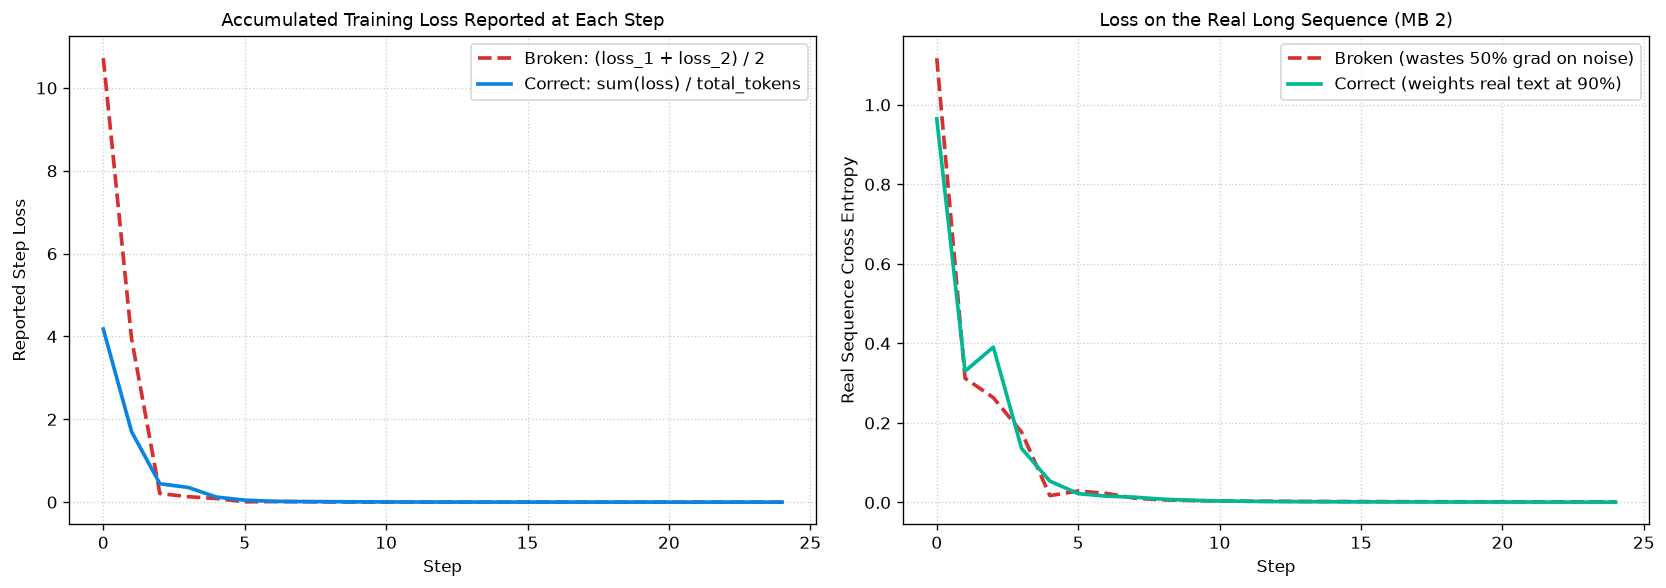

<All keys matched successfully>

In [11]:
# 1. Micro-batch 1: 4 random token IDs (very high loss)                                                                                                                        
torch.manual_seed(123)                                                                                                                                                      
short_ids = torch.randint(2000, 200000, (1, 5), device=model.device)                                                                                                        
enc_short = {"input_ids": short_ids}                                                                                                                                        
                                                                                                                                                                            
# 2. Micro-batch 2: 39 tokens of real text (lower loss)                                                                                                                     
seq_long = (                                                                                                                                                                
    "Elephants are the largest living land animals. Distinctive features include a long "                                                                                   
    "proboscis called a trunk, tusks, large ear flaps, pillar-like legs, and tough grey skin."                                                                              
)                                                                                                                                                                           
enc_long = tok(seq_long, return_tensors="pt").to(model.device)                                                                                                              
                                                                                                                                                                            
micro_batches = [enc_short, enc_long]                                                                                                                                       
tokens_short = enc_short["input_ids"].size(1) - 1                                                                                                                           
tokens_long = enc_long["input_ids"].size(1) - 1                                                                                                                             
total_tokens = tokens_short + tokens_long                                                                                                                                   
K = len(micro_batches)                                                                                                                                                      
                                                                                                                                                                            
# Measure baseline losses using logits.size(-1)                                                                                                                             
with torch.no_grad():                                                                                                                                                       
    logits_short = model(**enc_short).logits[:, :-1, :]                                                                                                                     
    l_short_init = F.cross_entropy(                                                                                                                                         
        logits_short.reshape(-1, logits_short.size(-1)),                                                                                                                    
        enc_short["input_ids"][:, 1:].reshape(-1),                                                                                                                          
    ).item()                                                                                                                                                                
                                                                                                                                                                            
    logits_long = model(**enc_long).logits[:, :-1, :]                                                                                                                       
    l_long_init = F.cross_entropy(                                                                                                                                          
        logits_long.reshape(-1, logits_long.size(-1)),                                                                                                                      
        enc_long["input_ids"][:, 1:].reshape(-1),                                                                                                                           
    ).item()                                                                                                                                                                
                                                                                                                                                                            
broken_start = (l_short_init + l_long_init) / 2                                                                                                                             
correct_start = (                                                                                                                                                           
    tokens_short * l_short_init + tokens_long * l_long_init                                                                                                                 
) / total_tokens                                                                                                                                                            
                                                                                                                                                                            
print("=" * 70)                                                                                                                                                             
print(f"STEP 0 STARTING VALUES:")                                                                                                                                           
print(f"Short noisy batch loss:      {l_short_init:.4f}")                                                                                                                   
print(f"Long real batch loss:       {l_long_init:.4f}")                                                                                                                     
print(f"Broken accumulation loss:   {broken_start:.4f}  <-- ({l_short_init} + {l_long_init}) / 2")                                                                                              
print(                                                                                                                                                                      
    f"Correct accumulation loss:  {correct_start:.4f}  <-- weighted by {tokens_short}/{total_tokens} vs {tokens_long}/{total_tokens}"                                       
)                                                                                                                                                                           
print("=" * 70)                                                                                                                                                             
                                                                                                                                                                            
# Save clean state                                                                                                                                                          
saved_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}                                                                                                 
                                                                                                                                                                            
num_steps = 25                                                                                                                                                              
lr = 2e-5                                                                                                                                                                   
                                                                                                                                                                            
# -----------------------------------------------------------------------------                                                                                             
# Run 1: Broken Accumulation                                                                                                                                                
# -----------------------------------------------------------------------------                                                                                             
model.train()                                                                                                                                                               
opt_broken = torch.optim.AdamW(model.parameters(), lr=lr)                                                                                                                   
broken_step_losses = []                                                                                                                                                     
broken_real_losses = []                                                                                                                                                     
                                                                                                                                                                            
for step in range(num_steps):                                                                                                                                               
    opt_broken.zero_grad(set_to_none=True)                                                                                                                                  
                                                                                                                                                                            
    accumulated_loss = 0.0                                                                                                                                                  
    for mb in micro_batches:                                                                                                                                                
        out = model(**mb)                                                                                                                                                   
        logits = out.logits[:, :-1, :]                                                                                                                                      
        targets = mb["input_ids"][:, 1:]                                                                                                                                    
                                                                                                                                                                            
        # Average of averages: mean over batch, then divided by K                                                                                                           
        l_mb = F.cross_entropy(                                                                                                                                             
            logits.reshape(-1, logits.size(-1)),                                                                                                                            
            targets.reshape(-1),                                                                                                                                            
            reduction="mean",                                                                                                                                               
        )                                                                                                                                                                   
        scaled_loss = l_mb / K                                                                                                                                              
        scaled_loss.backward()                                                                                                                                              
        accumulated_loss += scaled_loss.item()                                                                                                                              
                                                                                                                                                                            
    opt_broken.step()                                                                                                                                                       
    broken_step_losses.append(accumulated_loss)                                                                                                                             
                                                                                                                                                                            
    # Measure performance on real data                                                                                                                                      
    with torch.no_grad():                                                                                                                                                   
        out_real = model(**enc_long)                                                                                                                                        
        logits_real = out_real.logits[:, :-1, :]                                                                                                                            
        l_real = F.cross_entropy(                                                                                                                                           
            logits_real.reshape(-1, logits_real.size(-1)),                                                                                                                  
            enc_long["input_ids"][:, 1:].reshape(-1),                                                                                                                       
        ).item()                                                                                                                                                            
        broken_real_losses.append(l_real)                                                                                                                                   
                                                                                                                                                                            
# -----------------------------------------------------------------------------                                                                                             
# Run 2: Correct Accumulation                                                                                                                                               
# -----------------------------------------------------------------------------                                                                                             
model.load_state_dict({k: v.to(model.device) for k, v in saved_weights.items()})                                                                                            
opt_correct = torch.optim.AdamW(model.parameters(), lr=lr)                                                                                                                  
correct_step_losses = []                                                                                                                                                    
correct_real_losses = []                                                                                                                                                    
                                                                                                                                                                            
for step in range(num_steps):                                                                                                                                               
    opt_correct.zero_grad(set_to_none=True)                                                                                                                                 
                                                                                                                                                                            
    accumulated_loss = 0.0                                                                                                                                                  
    for mb in micro_batches:                                                                                                                                                
        out = model(**mb)                                                                                                                                                   
        logits = out.logits[:, :-1, :]                                                                                                                                      
        targets = mb["input_ids"][:, 1:]                                                                                                                                    
                                                                                                                                                                            
        # Global token average: sum over batch, divided by total tokens                                                                                                     
        l_mb_sum = F.cross_entropy(                                                                                                                                         
            logits.reshape(-1, logits.size(-1)),                                                                                                                            
            targets.reshape(-1),                                                                                                                                            
            reduction="sum",                                                                                                                                                
        )                                                                                                                                                                   
        scaled_loss = l_mb_sum / total_tokens                                                                                                                               
        scaled_loss.backward()                                                                                                                                              
        accumulated_loss += scaled_loss.item()                                                                                                                              
                                                                                                                                                                            
    opt_correct.step()                                                                                                                                                      
    correct_step_losses.append(accumulated_loss)                                                                                                                            
                                                                                                                                                                            
    # Measure performance on real data                                                                                                                                      
    with torch.no_grad():                                                                                                                                                   
        out_real = model(**enc_long)                                                                                                                                        
        logits_real = out_real.logits[:, :-1, :]                                                                                                                            
        l_real = F.cross_entropy(                                                                                                                                           
            logits_real.reshape(-1, logits_real.size(-1)),                                                                                                                  
            enc_long["input_ids"][:, 1:].reshape(-1),                                                                                                                       
        ).item()                                                                                                                                                            
        correct_real_losses.append(l_real)                                                                                                                                  

# -----------------------------------------------------------------------------
# Plots
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Left: What the training loop actually calculates and reports
ax1.plot(
    broken_step_losses,
    label="Broken: (loss_1 + loss_2) / 2",
    color="#d63031",
    linewidth=2.2,
    linestyle="--",
)
ax1.plot(
    correct_step_losses,
    label="Correct: sum(loss) / total_tokens",
    color="#0984e3",
    linewidth=2.2,
)
ax1.set_title("Accumulated Training Loss Reported at Each Step", fontsize=11)
ax1.set_xlabel("Step")
ax1.set_ylabel("Reported Step Loss")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Right: Loss specifically on the real text
ax2.plot(
    broken_real_losses,
    label="Broken (wastes 50% grad on noise)",
    color="#d63031",
    linewidth=2.2,
    linestyle="--",
)
ax2.plot(
    correct_real_losses,
    label="Correct (weights real text at 90%)",
    color="#00b894",
    linewidth=2.2,
)
ax2.set_title("Loss on the Real Long Sequence (MB 2)", fontsize=11)
ax2.set_xlabel("Step")
ax2.set_ylabel("Real Sequence Cross Entropy")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Restore initial model weights
model.load_state_dict({k: v.to(model.device) for k, v in saved_weights.items()})

## Loss vs Grad Norm

Grad norm moved before loss at Step 11:
  Step 10: Loss = 0.0011 | Grad Norm = 0.1807
  Step 11:   Loss = 0.0010 | Grad Norm = 0.2334
  Step 12: Loss = 0.0013 | Grad Norm = 0.3496


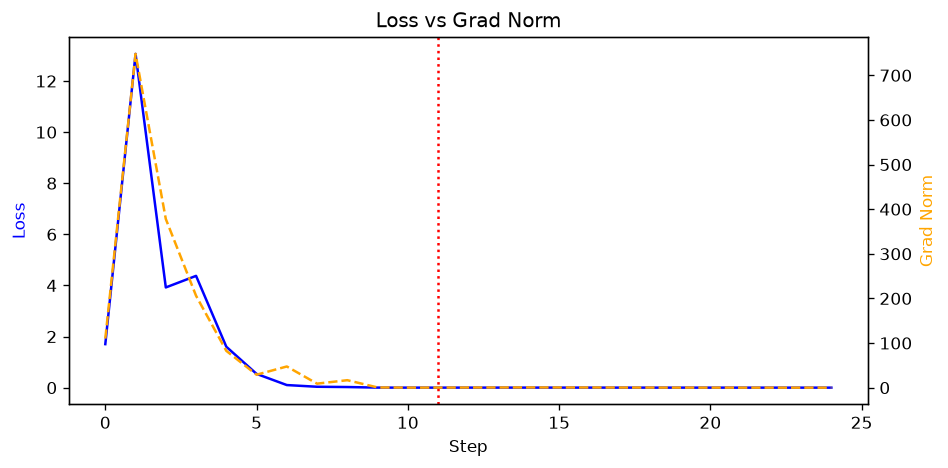

In [13]:
enc = tok(                                                                                                                                                                  
    "The capital of India is New Delhi. The capital of France is Paris.",                                                                                                   
    return_tensors="pt",                                                                                                                                                    
).to(model.device)                                                                                                                                                          
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)                                                                                                                        
                                                                                                                                                                            
losses, norms = [], []                                                                                                                                                      

for _ in range(25):
    opt.zero_grad(set_to_none=True)
    out = model(**enc)
    loss = F.cross_entropy(
        out.logits[:, :-1, :].reshape(-1, out.logits.size(-1)),
        enc["input_ids"][:, 1:].reshape(-1),
    )
    loss.backward()

# Log gradient norm before optimizer step
    norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), float("inf")
    ).item()
    opt.step()

    losses.append(loss.item())
    norms.append(norm)

# Find the step with the highest ratio of (% change in norm) / (% change in loss)
ratios = [
    (abs(norms[i] - norms[i - 1]) / norms[i - 1])
    / (abs(losses[i] - losses[i - 1]) / losses[i - 1] + 1e-4)
    for i in range(1, len(losses))
]
lead_step = ratios.index(max(ratios)) + 1

print(
    f"Grad norm moved before loss at Step {lead_step}:"
    f"\n  Step {lead_step-1}: Loss = {losses[lead_step-1]:.4f} | Grad Norm = {norms[lead_step-1]:.4f}"
    f"\n  Step {lead_step}:   Loss = {losses[lead_step]:.4f} | Grad Norm = {norms[lead_step]:.4f}"
    f"\n  Step {lead_step+1}: Loss = {losses[lead_step+1]:.4f} | Grad Norm = {norms[lead_step+1]:.4f}"
)

# Plot
fig, ax1 = plt.subplots(figsize=(8, 4), dpi=120)
ax2 = ax1.twinx()

ax1.plot(losses, color="blue", label="Loss")
ax2.plot(norms, color="orange", linestyle="--", label="Grad Norm")
ax1.axvline(
    lead_step, color="red", linestyle=":", label=f"Lead Step ({lead_step})"
)

ax1.set_xlabel("Step")
ax1.set_ylabel("Loss", color="blue")
ax2.set_ylabel("Grad Norm", color="orange")
ax1.set_title("Loss vs Grad Norm")
plt.tight_layout()
plt.show()

## Calculate MFU

In [3]:
import matplotlib.pyplot as plt                                                                                                                                             
import torch                                                                                                                                                                
import torch.nn.functional as F                                                                                                                                             
                                                                                                                                                                            
PEAK_TFLOPS = 154.8  # RTX A6000 dense BF16 peak                                                                                                                            
                                                                                                                                                                            
# 1. Create a large token stream and pack into [B, 2048]                                                                                                                    
B = 1  # Start with B=1 (2,048 tokens). You can try B=2 (4,096 tokens) on your 48 GB VRAM.                                                                                  
SEQ_LEN = 2048                                                                                                                                                              
                                                                                                                                                                            
sample_paragraph = (                                                                                                                                                        
    "Elephants are the largest living land animals on Earth. Three living species are currently recognised: "                                                               
    "the African bush elephant, the African forest elephant, and the Asian elephant. "                                                                                      
    "Distinctive features include a long proboscis called a trunk, tusks, large ear flaps, pillar-like legs, "                                                              
    "and tough but sensitive grey skin. The trunk is prehensile, bringing food and water to the mouth. "                                                                    
    "Tusks, which are derived from the incisor teeth, serve both as weapons and as tools for moving objects. "                                                              
)                                                                                                                                                                           
                                                                                                                                                                            
# Repeat text with EOS boundaries to build a large corpus                                                                                                                   
long_text = (sample_paragraph + tok.eos_token) * 35                                                                                                                         
all_token_ids = tok(long_text, return_tensors="pt")["input_ids"][0]                                                                                                         
                                                                                                                                                                            
# Ensure we have enough tokens, slice, and reshape to [B, 2048]                                                                                                             
required_tokens = B * SEQ_LEN                                                                                                                                               
assert (                                                                                                                                                                    
    len(all_token_ids) >= required_tokens                                                                                                                                   
), f"Need {required_tokens} tokens, got {len(all_token_ids)}"                                                                                                               
                                                                                                                                                                            
batch_input_ids = all_token_ids[:required_tokens].view(B, SEQ_LEN).to(model.device)                                                                                         
batch_labels = batch_input_ids.clone()                                                                                                                                      
                                                                                                                                                                            
print("=" * 65)                                                                                                                                                             
print(f"BATCH SHAPE:          {tuple(batch_input_ids.shape)}  (Batch={B}, SeqLen={SEQ_LEN})")                                                                               
print(f"TOTAL TOKENS IN STEP: {batch_input_ids.numel():,}")                                                                                                                 
print("=" * 65)                                                                                                                                                             
                                                                                                                                                                            
# 2. Setup benchmark variables                                                                                                                                              
num_tokens = B * (SEQ_LEN - 1)                                                                                                                                              
total_params = sum(p.numel() for p in model.parameters())                                                                                                                   
flops_per_step = 6 * total_params * num_tokens

model.train()
opt = torch.optim.AdamW(model.parameters(), lr=1e-5)

# Warm-up (2 steps)
for _ in range(2):
    opt.zero_grad(set_to_none=True)
    out = model(input_ids=batch_input_ids)
    loss = F.cross_entropy(
        out.logits[:, :-1, :].reshape(-1, out.logits.size(-1)),
        batch_labels[:, 1:].reshape(-1),
    )
    loss.backward()
    opt.step()

torch.cuda.synchronize()

# Benchmark over 5 steps
num_benchmark_steps = 5
start_event = torch.cuda.Event(enable_timing=True)
end_event = torch.cuda.Event(enable_timing=True)

start_event.record()
for _ in range(num_benchmark_steps):
    opt.zero_grad(set_to_none=True)
    out = model(input_ids=batch_input_ids)
    loss = F.cross_entropy(
        out.logits[:, :-1, :].reshape(-1, out.logits.size(-1)),
        batch_labels[:, 1:].reshape(-1),
    )
    loss.backward()
    opt.step()
end_event.record()

torch.cuda.synchronize()

step_time_ms = start_event.elapsed_time(end_event) / num_benchmark_steps
step_time_sec = step_time_ms / 1000.0

achieved_tflops = (flops_per_step / step_time_sec) / 1e12
mfu = (achieved_tflops / PEAK_TFLOPS) * 100.0

print(f"Tokens Per Step:		  {num_tokens:,}")
print(f"Step Time:                    {step_time_ms:.2f} ms")
print(f"Achieved Throughput:          {achieved_tflops:.2f} TFLOP/s")
print(f"MODEL FLOPS UTILIZATION:  {mfu:.2f}%")
print("=" * 65)

BATCH SHAPE:          (1, 2048)  (Batch=1, SeqLen=2048)
TOTAL TOKENS IN STEP: 2,048
Tokens Per Step:		  2,047
Step Time:                    278.93 ms
Achieved Throughput:          37.56 TFLOP/s
MODEL FLOPS UTILIZATION:  24.26%


The MFU is much lower then anticipated 40% due to various reasons, of smaller batch size, the `causal-conv1d` missing for linear attention kernels, falling back to slower pytorch implementation etc

## 0.1 in Float 32, BFloat16 and FP8

In [4]:
val = 0.1                                                                                                                                                                   
                                                                                                                                                                            
# 1. FP32                                                                                                                                                                   
t_fp32 = torch.tensor(val, dtype=torch.float32)                                                                                                                             
bits_32 = f"{t_fp32.view(torch.int32).item() & 0xFFFFFFFF:032b}"                                                                                                            
s32, e32, m32 = bits_32[0], bits_32[1:9], bits_32[9:]

# 2. BF16
t_bf16 = torch.tensor(val, dtype=torch.bfloat16)
bits_16 = f"{t_bf16.view(torch.int16).item() & 0xFFFF:016b}"
s16, e16, m16 = bits_16[0], bits_16[1:9], bits_16[9:]

# 3. FP8 E4M3
t_fp8 = torch.tensor(val, dtype=torch.float8_e4m3fn)
bits_8 = f"{t_fp8.view(torch.uint8).item():08b}"
s8, e8, m8 = bits_8[0], bits_8[1:5], bits_8[5:]
val_fp8 = t_fp8.float().item()

print("=" * 70)
print(f"BIT PATTERNS FOR DECIMAL: {val}")
print("=" * 70)

print("1. FP32 (Single Precision)")
print(f"   Raw Bits:     {s32} | {e32} | {m32}")
print(f"                 S   Exp (8b)  Mantissa (23b)")
print(f"   Hex:          0x{t_fp32.view(torch.int32).item() & 0xFFFFFFFF:08X}")
print(f"   Stored Value: {t_fp32.item():.17f}")
print(f"   Error:        {abs(t_fp32.item() - val):.17f}")
print()

print("2. BF16 (Brain Floating Point)")
print(f"   Raw Bits:     {s16} | {e16} | {m16}")
print(f"                 S   Exp (8b)  Mantissa (7b)")
print(f"   Hex:          0x{t_bf16.view(torch.int16).item() & 0xFFFF:04X}")
print(f"   Stored Value: {t_bf16.float().item():.17f}")
print(f"   Error:        {abs(t_bf16.float().item() - val):.17f}")
print()

print("3. FP8 E4M3 (NVIDIA / OCP)")
print(f"   Raw Bits:     {s8} | {e8} | {m8}")
print(f"                 S  Exp(4b) Mant(3b)")
print(f"   Hex:          0x{int(bits_8, 2):02X}")
print(f"   Stored Value: {val_fp8:.17f}")
print(f"   Error:        {abs(val_fp8 - val):.17f}")
print("=" * 70)

BIT PATTERNS FOR DECIMAL: 0.1
1. FP32 (Single Precision)
   Raw Bits:     0 | 01111011 | 10011001100110011001101
                 S   Exp (8b)  Mantissa (23b)
   Hex:          0x3DCCCCCD
   Stored Value: 0.10000000149011612
   Error:        0.00000000149011611

2. BF16 (Brain Floating Point)
   Raw Bits:     0 | 01111011 | 1001101
                 S   Exp (8b)  Mantissa (7b)
   Hex:          0x3DCD
   Stored Value: 0.10009765625000000
   Error:        0.00009765624999999

3. FP8 E4M3 (NVIDIA / OCP)
   Raw Bits:     0 | 0011 | 101
                 S  Exp(4b) Mant(3b)
   Hex:          0x1D
   Stored Value: 0.10156250000000000
   Error:        0.00156249999999999
